# Preprocessing

In [1]:
%matplotlib inline

import pandas as pd

pd.set_option('display.max_columns', 10)

In [2]:
raw = pd.read_csv('telecom_bill.csv')
raw.head()

,ID,churn,join_time,vip,product,expenditure,call,traffic,state,IMEI
0,1,1,2014/8/19,0,99114783,0.000,0.00,0.00,0.0,NaN
1,2,0,2014/6/16,0,99002147,42.843,35.91,254.06,0.0,35405402.0
2,3,0,2014/8/2,0,99002138,125.198,309.73,162.56,0.0,35246506.0
3,4,0,2012/9/13,0,99005934,103.546,410.64,119.50,0.0,86399002.0
4,5,0,2012/12/20,0,99005044,0.000,0.00,0.00,1.0,NaN


### Wrong Value Processing

In [3]:
raw[raw.traffic >= 5000].head()

,ID,churn,join_time,vip,product,expenditure,call,traffic,state,IMEI
1618,1619,0,2014/10/1,0,25210,226.933,0.0,9428.06,1.0,NaN
1619,1620,0,2014/2/16,0,25210,102.557,0.0,5348.51,1.0,NaN
2831,2832,0,2006/6/12,0,3039,85.763,106.7,6275.32,NaN,1294300.0


In [4]:
data = raw[raw.traffic < 5000].copy()

In [5]:
statesCount = data['ID'].groupby(data.state).count()
statesCount.head(10)

state
0.0    1316
1.0     584
2.0       9
3.0     232
4.0      23
5.0     150
6.0     471
7.0     148
Name: ID, dtype: int64

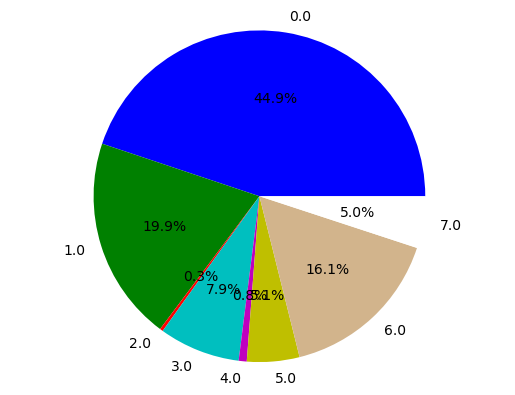

In [6]:
import matplotlib.pyplot as plt

plt.pie(statesCount.values, labels = statesCount.index,
        colors=('b','g','r','c','m','y','tan','w'), autopct='%1.1f%%')

# Equal aspect ratio ensures that pie is drawn as a circle.
plt.axis('equal')  
plt.show()

In [7]:
import numpy as np

new_state = data['state'].replace([2, 4], np.nan)

### Outlier Processing

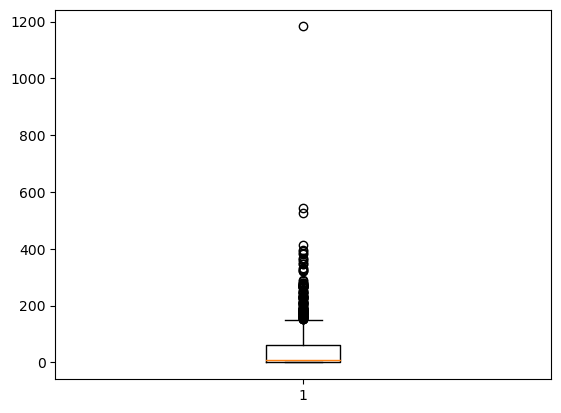

In [8]:
plt.boxplot(data.expenditure)
plt.show()

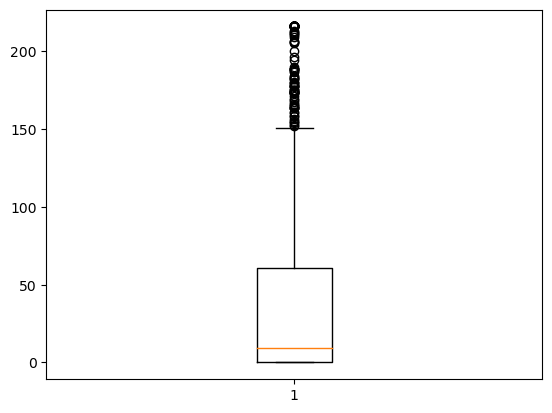

In [9]:
tmp = data.expenditure.copy()

# Compute boundray.
mu = data.expenditure.mean()
sigma = data.expenditure.std()
lb = mu - 3 * sigma
hb = mu + 3 * sigma

# Outier processing
tmp[tmp < lb] = lb
tmp[tmp > hb] = hb

plt.boxplot(tmp)
plt.show()

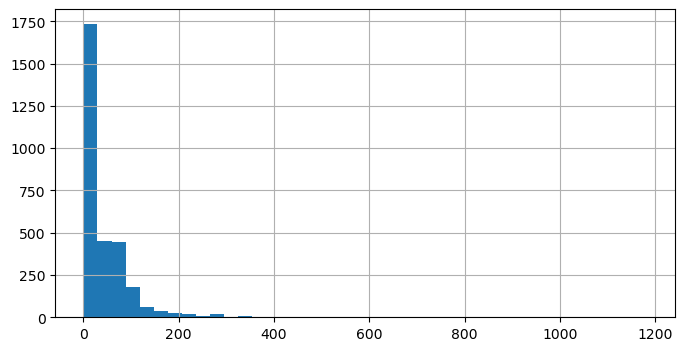

In [10]:
data.expenditure.hist(figsize=(8, 4), bins=40)
plt.show()

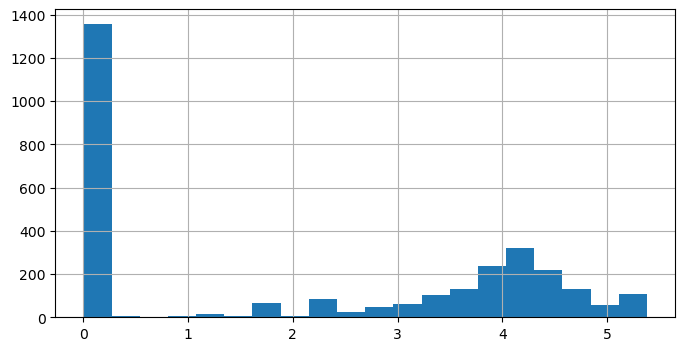

In [11]:
data['log_expd'] = np.log1p(tmp)  # 等同于np.log(tmp + 1)
data.log_expd.hist(figsize=(8, 4), bins=20)
plt.show()

In [12]:
from sklearn.preprocessing import FunctionTransformer

functionTF = FunctionTransformer(np.log1p)
log_data = functionTF.fit_transform(data[['call', 'traffic']])
data['log_call'] = log_data.iloc[:, 0]
data['log_traffic'] = log_data.iloc[:, 1]
data.head()

,ID,churn,join_time,vip,product,...,state,IMEI,log_expd,log_call,log_traffic
0,1,1,2014/8/19,0,99114783,...,0.0,NaN,0.000000,0.000000,0.000000
1,2,0,2014/6/16,0,99002147,...,0.0,35405402.0,3.780615,3.608483,5.541499
2,3,0,2014/8/2,0,99002138,...,0.0,35246506.0,4.837852,5.738924,5.097180
3,4,0,2012/9/13,0,99005934,...,0.0,86399002.0,4.649627,6.020149,4.791650
4,5,0,2012/12/20,0,99005044,...,1.0,NaN,0.000000,0.000000,0.000000


### Missing Data Imputation

In [13]:
data.count()

ID             2997
churn          2997
join_time      2997
vip            2997
product        2997
expenditure    2997
call           2997
traffic        2997
state          2933
IMEI            677
log_expd       2997
log_call       2997
log_traffic    2997
dtype: int64

In [14]:
data.isnull().sum()

ID                0
churn             0
join_time         0
vip               0
product           0
expenditure       0
call              0
traffic           0
state            64
IMEI           2320
log_expd          0
log_call          0
log_traffic       0
dtype: int64

In [15]:
data.dropna(thresh=1, subset=['state', 'IMEI']).count()

ID             2938
churn          2938
join_time      2938
vip            2938
product        2938
expenditure    2938
call           2938
traffic        2938
state          2933
IMEI            677
log_expd       2938
log_call       2938
log_traffic    2938
dtype: int64

In [16]:
# 将所有缺失值补位 0，但不替换。不适用于一般情况
data.fillna(value=0, inplace=False).head()

,ID,churn,join_time,vip,product,...,state,IMEI,log_expd,log_call,log_traffic
0,1,1,2014/8/19,0,99114783,...,0.0,0.0,0.000000,0.000000,0.000000
1,2,0,2014/6/16,0,99002147,...,0.0,35405402.0,3.780615,3.608483,5.541499
2,3,0,2014/8/2,0,99002138,...,0.0,35246506.0,4.837852,5.738924,5.097180
3,4,0,2012/9/13,0,99005934,...,0.0,86399002.0,4.649627,6.020149,4.791650
4,5,0,2012/12/20,0,99005044,...,1.0,0.0,0.000000,0.000000,0.000000


In [17]:
top_state = data['state'].mode()[0]
data.fillna({"IMEI": 0, "state": top_state}, inplace=True)
data.count()

ID             2997
churn          2997
join_time      2997
vip            2997
product        2997
expenditure    2997
call           2997
traffic        2997
state          2997
IMEI           2997
log_expd       2997
log_call       2997
log_traffic    2997
dtype: int64

In [18]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
imputer.fit_transform(raw[['state', 'IMEI']])

array([[0.0000000e+00, 8.6207302e+07],
       [0.0000000e+00, 3.5405402e+07],
       [0.0000000e+00, 3.5246506e+07],
       ...,
       [5.0000000e+00, 8.6207302e+07],
       [6.0000000e+00, 8.6207302e+07],
       [6.0000000e+00, 8.6207302e+07]])

### Binarization

In [19]:
from sklearn.preprocessing import Binarizer

binarizer = Binarizer(threshold=0, copy=True)
data['has_IMEI'] = binarizer.fit_transform(data[['IMEI',]])
data.head()

,ID,churn,join_time,vip,product,...,IMEI,log_expd,log_call,log_traffic,has_IMEI
0,1,1,2014/8/19,0,99114783,...,0.0,0.000000,0.000000,0.000000,0.0
1,2,0,2014/6/16,0,99002147,...,35405402.0,3.780615,3.608483,5.541499,1.0
2,3,0,2014/8/2,0,99002138,...,35246506.0,4.837852,5.738924,5.097180,1.0
3,4,0,2012/9/13,0,99005934,...,86399002.0,4.649627,6.020149,4.791650,1.0
4,5,0,2012/12/20,0,99005044,...,0.0,0.000000,0.000000,0.000000,0.0


In [20]:
pd.cut(data['IMEI'], bins=[-float('inf'), 0, float('inf')], 
       labels=False).head()

0    0
1    1
2    1
3    1
4    0
Name: IMEI, dtype: int64

### Discretization

等宽离散

In [21]:
from datetime import datetime

dura_col = datetime(2015, 1, 1) - pd.to_datetime(data['join_time'])
data['duration'] = dura_col.map(lambda x: x.days / 30.)

In [22]:
equal_width = pd.cut(data['duration'], 5)
data['churn'].groupby(equal_width).agg(['count', 'mean','sum'])

,count,mean,sum
duration,,,
"(1.892, 36.913]",2634,0.277145,730
"(36.913, 71.76]",271,0.177122,48
"(71.76, 106.607]",41,0.097561,4
"(106.607, 141.453]",30,0.066667,2
"(141.453, 176.3]",21,0.000000,0


In [23]:
sample_labels, retbins = pd.cut(data['duration'], 5, labels=range(5),
                                retbins=True)
print(sample_labels[:5])
print(retbins)

0    0
1    0
2    0
3    0
4    0
Name: duration, dtype: category
Categories (5, int64): [0 < 1 < 2 < 3 < 4]
[  1.89243333  36.91333333  71.76       106.60666667 141.45333333
 176.3       ]


等分离散
- 老版本的pandas的qcut方法有bug，现有修复

In [24]:
equal_depth = pd.qcut(data['duration'], 14)
discretization_dura = data['churn'].groupby(equal_depth).agg(
    ['count', 'mean','sum'])
discretization_dura.head()

,count,mean,sum
duration,,,
"(2.0660000000000003, 3.867]",222,0.094595,21
"(3.867, 4.433]",209,0.416268,87
"(4.433, 5.233]",215,0.302326,65
"(5.233, 6.1]",214,0.102804,22
"(6.1, 6.933]",216,0.032407,7


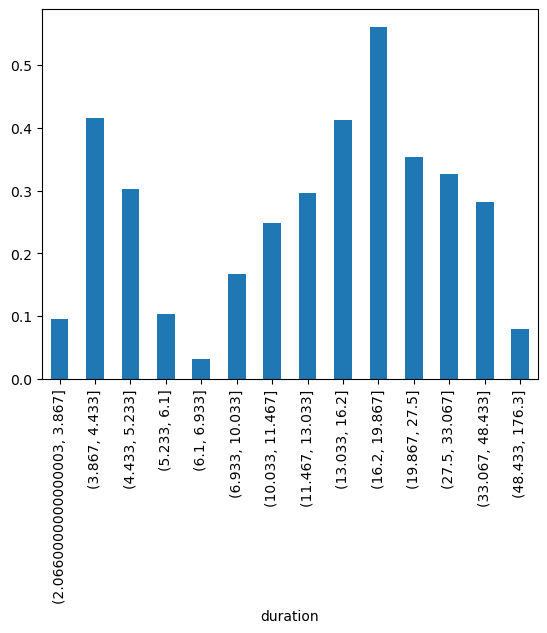

In [25]:
discretization_dura['mean'].plot(kind='bar')
plt.show()

人工离散

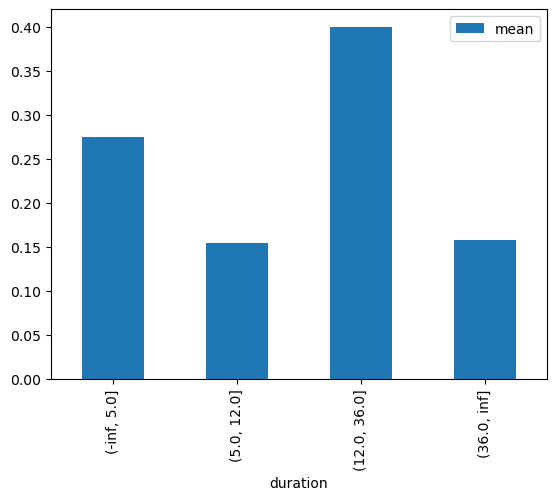

In [26]:
bins = [-np.inf, 5, 12, 36, np.inf]

artificial_width = pd.cut(data['duration'], bins)
data['churn'].groupby(artificial_width).agg(['mean']).plot(kind='bar')
plt.show()

### Dummy coding

In [27]:
dummies = pd.get_dummies(data.state, prefix='s')
data.join(dummies).head()

,ID,churn,join_time,vip,product,...,s_3.0,s_4.0,s_5.0,s_6.0,s_7.0
0,1,1,2014/8/19,0,99114783,...,0,0,0,0,0
1,2,0,2014/6/16,0,99002147,...,0,0,0,0,0
2,3,0,2014/8/2,0,99002138,...,0,0,0,0,0
3,4,0,2012/9/13,0,99005934,...,0,0,0,0,0
4,5,0,2012/12/20,0,99005044,...,0,0,0,0,0


In [28]:
from sklearn.preprocessing import OneHotEncoder

OneHotEncoder().fit_transform(data[['state',]]).toarray()

array([[1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.],
       [0., 0., 0., ..., 0., 1., 0.]])

### Standardization

In [29]:
from sklearn.preprocessing import StandardScaler

consumptions = data.loc[:, 'log_expd':'log_traffic']
std_scaler = StandardScaler()
std_data = std_scaler.fit_transform(consumptions)

In [30]:
std_df = pd.DataFrame(
    std_data, 
    columns=['s_expd','s_call','s_traffic'], 
    index=data.index
)

data1 = data.join(std_df)
data1.head()

,ID,churn,join_time,vip,product,...,has_IMEI,duration,s_expd,s_call,s_traffic
0,1,1,2014/8/19,0,99114783,...,0.0,4.500000,-1.033838,-0.858726,-0.736602
1,2,0,2014/6/16,0,99002147,...,1.0,6.633333,0.826886,0.444322,1.506040
2,3,0,2014/8/2,0,99002138,...,1.0,5.066667,1.347232,1.213640,1.326225
3,4,0,2012/9/13,0,99005934,...,1.0,28.000000,1.254592,1.315192,1.202577
4,5,0,2012/12/20,0,99005044,...,0.0,24.733333,-1.033838,-0.858726,-0.736602


In [31]:
from sklearn.preprocessing import MinMaxScaler

range_scaler = MinMaxScaler()
range_scaler.fit_transform(consumptions)[:5]

array([[0.        , 0.        , 0.        ],
       [0.70271184, 0.43909355, 0.65562565],
       [0.89922298, 0.69833362, 0.6030574 ],
       [0.86423716, 0.7325541 , 0.56690953],
       [0.        , 0.        , 0.        ]])

### Normalization

In [32]:
from sklearn.preprocessing import Normalizer

Normalizer().fit_transform(data1.iloc[:, -3:])

array([[-0.67457179, -0.56031252, -0.48062748],
       [ 0.46594788,  0.25037431,  0.84864909],
       [ 0.59969873,  0.5402324 ,  0.59034768],
       ...,
       [-0.67457179, -0.56031252, -0.48062748],
       [-0.67457179, -0.56031252, -0.48062748],
       [-0.67457179, -0.56031252, -0.48062748]])

# Feature Construction

In [33]:
# Duration has been constructed before
data1['unit_price'] = data1['expenditure'] / (data1['traffic'] + 1.)
data1['TAC'] = data1['IMEI'].map(lambda x: str(x)[:6])

data1.head()

,ID,churn,join_time,vip,product,...,s_expd,s_call,s_traffic,unit_price,TAC
0,1,1,2014/8/19,0,99114783,...,-1.033838,-0.858726,-0.736602,0.000000,0.0
1,2,0,2014/6/16,0,99002147,...,0.826886,0.444322,1.506040,0.167972,354054
2,3,0,2014/8/2,0,99002138,...,1.347232,1.213640,1.326225,0.765456,352465
3,4,0,2012/9/13,0,99005934,...,1.254592,1.315192,1.202577,0.859303,863990
4,5,0,2012/12/20,0,99005044,...,-1.033838,-0.858726,-0.736602,0.000000,0.0


# Feature Extraction

### PCA

In [34]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, whiten=True)
pca.fit_transform(data1[['s_expd','s_call', 's_traffic']])

array([[-0.94736281,  0.29963145],
       [ 0.98959834,  1.32673399],
       [ 1.39739869,  0.12575804],
       ...,
       [-0.94736281,  0.29963145],
       [-0.94736281,  0.29963145],
       [-0.94736281,  0.29963145]])

In [35]:
pca.explained_variance_ratio_ # 每个主成分能解释的变异值的百分比

array([0.85822378, 0.09243186])

In [36]:
pca.explained_variance_  # 每个主成分能解释的变异值

array([2.5755307 , 0.27738814])

In [37]:
pca.components_  # 主成分方向

array([[ 0.58179202,  0.58842852,  0.56148902],
       [-0.48649622, -0.30147075,  0.82002245]])

In [38]:
# 手动构造一个伪测试集，并投影到训练集构造的主成分方向上
pca.transform(
    pd.DataFrame( 
        data=[[-1, 0, 1], [1, 2, 3]], 
        columns=['s_expd','s_call', 's_traffic'])
)

array([[-0.01265105,  2.48068533],
       [ 2.14544955,  2.60241273]])

### LDA

In [39]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis()
lda.fit_transform(data1[['s_expd', 's_call', 's_traffic']], data1.churn)

array([[-1.27619422],
       [ 0.98557605],
       [ 1.66242273],
       ...,
       [-1.27619422],
       [-1.27619422],
       [-1.27619422]])

In [40]:
lda.coef_  # 投影的方向

array([[-1.96715146, -0.11574441,  0.03274378]])

In [41]:
# 对人工造的测试集进行特征转换（投影）
lda.transform(
    pd.DataFrame(
        [[-1, 0, 1],[1, 2, 3]],
        columns=['s_expd', 's_call', 's_traffic']
    )
)

array([[-1.21017906],
       [ 1.27100205]])

In [42]:
# 线性判别分析可以直接作为分类器模型
prediction = lda.predict(data1[['s_expd','s_call','s_traffic']])
result = prediction == data1.churn
result.mean()  # 预测的准确率

0.7881214547881215

# Feature Selection

### Filter

方差过滤

In [43]:
from sklearn.feature_selection import VarianceThreshold

var_th = VarianceThreshold(threshold=0.09)
var_th.fit_transform(data1[['vip', 'has_IMEI']])

array([[0.],
       [1.],
       [1.],
       ...,
       [0.],
       [0.],
       [0.]])

In [44]:
# 各个变量的方差
var_th.variances_

array([0.00761545, 0.17468208])

卡方检验

In [45]:
# 将待选特征与目标变量按照类型进行划分
x_categorical = data1[['vip', 'state', 'has_IMEI']]
x_continuous = data1[['s_expd', 's_call', 's_traffic', 'duration']]
y_categorical = data1['churn']
y_continuous = data1['s_expd']

In [46]:
from sklearn.feature_selection import chi2

# 两个离散变量的相关性可以使用卡方检验
chi2(x_categorical, y_categorical) 

(array([   8.14821509, 1548.56516691,  234.10022178]),
 array([4.31035658e-03, 0.00000000e+00, 7.60652200e-53]))

In [47]:
from sklearn.feature_selection import SelectKBest

# 通过卡方检验保留与目标变量最相关的两个变量
selector = SelectKBest(chi2, k=2).fit(x_categorical, y_categorical)
selector.transform(x_categorical)

array([[0., 0.],
       [0., 1.],
       [0., 1.],
       ...,
       [5., 0.],
       [6., 0.],
       [6., 0.]])

In [48]:
# 查看被筛选掉的变量

selector.get_support()

array([False,  True,  True])

ANOVA

In [49]:
from sklearn.feature_selection import f_classif

# ANOVA用于判断连续变量和离散变量的相关程度
f_classif(x_continuous, y_categorical)

(array([1579.15667007, 1037.31259793,  702.52362415,    7.11982692]),
 array([9.61271589e-278, 1.10905936e-195, 3.02903316e-139, 7.66469566e-003]))

In [50]:
# 强行保留与目标变量最相关的两个连续变量
f_classif_selector = SelectKBest(f_classif, k=2)
print(f_classif_selector.fit_transform(x_continuous, y_categorical))
# f_classif_selector.get_support()  # 输出被筛选掉的变量

[[-1.0338379  -0.85872599]
 [ 0.82688629  0.44432241]
 [ 1.34723192  1.21363993]
 ...
 [-1.0338379  -0.85872599]
 [-1.0338379  -0.85872599]
 [-1.0338379  -0.85872599]]


In [51]:
f_classif_selector.get_support()

array([ True,  True, False, False])

相关系数

In [52]:
from sklearn.feature_selection import f_regression

# 相关系数用于分析连续变量之间的相关性
f_regression(x_continuous, y_continuous)

(array([-3.06551838e+17,  7.77805369e+03,  3.65008855e+03,  9.75679205e+01]),
 array([1.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.15092751e-22]))

In [53]:
# 保留与消费金额最相关的两个变量
f_regression_selector = SelectKBest(f_regression, k=2)
print(f_regression_selector.fit_transform(x_continuous, y_continuous))


[[-0.85872599 -0.73660197]
 [ 0.44432241  1.50604033]
 [ 1.21363993  1.32622464]
 ...
 [-0.85872599 -0.73660197]
 [-0.85872599 -0.73660197]
 [-0.85872599 -0.73660197]]


In [54]:
# 查看被筛选掉的变量
f_regression_selector.get_support() 

array([False,  True,  True, False])

### Wrapper

In [55]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

# RFE是Recursive Feature Elimination（递归特征消除）的缩写
rfe = RFE(estimator=LogisticRegression(), n_features_to_select=2) # 保留两个特征
rfe.fit_transform(x_continuous, y_categorical)

array([[-1.0338379 , -0.73660197],
       [ 0.82688629,  1.50604033],
       [ 1.34723192,  1.32622464],
       ...,
       [-1.0338379 , -0.73660197],
       [-1.0338379 , -0.73660197],
       [-1.0338379 , -0.73660197]])

In [56]:
rfe.get_support()

array([ True, False,  True, False])

### Embedded

In [57]:
from sklearn.ensemble import RandomForestClassifier

# 很多模型天然具有生成变量重要性的能力，例如随机森林
rfc = RandomForestClassifier()
rfc.fit(x_continuous, y_categorical)

list(zip(x_continuous.columns, rfc.feature_importances_))

[('s_expd', 0.33032417750938486),
 ('s_call', 0.1203424187761637),
 ('s_traffic', 0.05994784676084859),
 ('duration', 0.48938555695360286)]

In [58]:
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import GradientBoostingClassifier

# GBDT模型也具有生成变量重要性的能力
gbdt_selector = SelectFromModel(GradientBoostingClassifier(),
                                threshold='mean')
gbdt_selector.fit_transform(x_continuous, y_categorical)

array([[-1.0338379 ,  4.5       ],
       [ 0.82688629,  6.63333333],
       [ 1.34723192,  5.06666667],
       ...,
       [-1.0338379 , 14.73333333],
       [-1.0338379 , 16.5       ],
       [-1.0338379 , 19.46666667]])

In [59]:
gbdt_selector.get_support()

array([ True, False, False,  True])